# EDA — Predicción de Severidad de Accidentes de Tránsito
**Curso:** Machine Learning Applied — Short-Paper

**Autores:** Jose Muñoz Ríos, Santiago Álvarez Peña

**Dataset:** *Road Traffic Accident Dataset of Addis Ababa City* (T. T. Bedane, Mendeley Data, 2020, doi:10.17632/xytv86278f.1; también en Kaggle: `saurabhshahane/road-traffic-accidents`).

Este notebook contiene el análisis exploratorio completo que respalda las cifras de las Secciones IV (Caracterización de los datos) y V (EDA) del short-paper. El entrenamiento y la evaluación de modelos están en `modelado.ipynb`. Flujo:

1. Estructura general, granularidad y estadísticas descriptivas del dataset crudo (`RTA_Dataset.csv`).
2. Calidad de datos: valores faltantes, duplicados y valores atípicos / categorías raras.
3. Limpieza reproducible → genera `cleaned.csv` (22 predictoras + target).
4. Distribución del target y línea base (hallazgo A).
5. Asociación de cada variable con la severidad (χ² y V de Cramér).
6. Hallazgos B (número de vehículos) y C (condiciones de luz y hora), y análisis complementarios.
7. Generación de figuras: la Fig. 1 del paper y una figura complementaria de asociación (`figuras/`).

Dependencias: `pandas`, `numpy`, `matplotlib`, `scipy`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

raw = pd.read_csv('RTA_Dataset.csv')
raw.shape

(12316, 32)

## 1. Estructura general del dataset crudo

In [2]:
raw.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,Residential areas,NaN,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,Office areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,Recreational areas,other,NaN,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,2,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,01:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,Office areas,other,Tangent road with mild grade and flat terrain,Y Shape,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,01:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,Industrial areas,other,Tangent road with flat terrain,Y Shape,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 1   Day_of_week                  12316 non-null  object
 2   Age_band_of_driver           12316 non-null  object
 3   Sex_of_driver                12316 non-null  object
 4   Educational_level            11575 non-null  object
 5   Vehicle_driver_relation      11737 non-null  object
 6   Driving_experience           11487 non-null  object
 7   Type_of_vehicle              11366 non-null  object
 8   Owner_of_vehicle             11834 non-null  object
 9   Service_year_of_vehicle      8388 non-null   object
 10  Defect_of_vehicle            7889 non-null   object
 11  Area_accident_occured        12077 non-null  object
 12  Lanes_or_Medians             11931 non-null  object
 13  Road_allignment              12

In [4]:
n_text = raw.select_dtypes(exclude='number').shape[1]
n_num = raw.select_dtypes(include='number').shape[1]
print(f'Filas: {raw.shape[0]:,} | Columnas: {raw.shape[1]} (texto/categóricas: {n_text}, numéricas: {n_num})')
print('Columnas numéricas:', raw.select_dtypes(include='number').columns.tolist())
print('Predictoras (sin contar el target):', raw.shape[1] - 1)

Filas: 12,316 | Columnas: 32 (texto/categóricas: 30, numéricas: 2)
Columnas numéricas: ['Number_of_vehicles_involved', 'Number_of_casualties']
Predictoras (sin contar el target): 31


**Observación:** el dataset crudo tiene **12,316 filas y 32 columnas**: la variable objetivo `Accident_severity` y **31 predictoras**, de las cuales 29 son categóricas (texto, incluida `Time`) y 2 numéricas discretas (`Number_of_vehicles_involved`, `Number_of_casualties`).

## 2. Granularidad: ¿una fila por accidente?

In [5]:
cols_evento = ['Time', 'Day_of_week', 'Number_of_vehicles_involved', 'Number_of_casualties',
               'Light_conditions', 'Weather_conditions', 'Road_surface_conditions']
raw[cols_evento + ['Age_band_of_driver', 'Type_of_vehicle', 'Accident_severity']].head(12)

,Time,Day_of_week,Number_of_vehicles_involved,Number_of_casualties,Light_conditions,Weather_conditions,Road_surface_conditions,Age_band_of_driver,Type_of_vehicle,Accident_severity
0,17:02:00,Monday,2,2,Daylight,Normal,Dry,18-30,Automobile,Slight Injury
1,17:02:00,Monday,2,2,Daylight,Normal,Dry,31-50,Public (> 45 seats),Slight Injury
2,17:02:00,Monday,2,2,Daylight,Normal,Dry,18-30,Lorry (41?100Q),Serious Injury
3,01:06:00,Sunday,2,2,Darkness - lights lit,Normal,Dry,18-30,Public (> 45 seats),Slight Injury
4,01:06:00,Sunday,2,2,Darkness - lights lit,Normal,Dry,18-30,NaN,Slight Injury
5,14:15:00,Friday,1,1,Daylight,Normal,Dry,31-50,NaN,Slight Injury
6,17:30:00,Wednesday,1,1,Daylight,Normal,Dry,18-30,Automobile,Slight Injury
7,17:20:00,Friday,2,1,Daylight,Normal,Dry,18-30,Automobile,Slight Injury
8,17:20:00,Friday,2,1,Daylight,Normal,Dry,18-30,Lorry (41?100Q),Slight Injury
9,17:20:00,Friday,2,1,Daylight,Normal,Dry,18-30,Automobile,Serious Injury


In [6]:
# Agrupamos filas que comparten hora, día y condiciones del evento (identificador aproximado de siniestro)
grupos = raw.groupby(cols_evento, dropna=False)
tam = grupos.size()
sev_distintas = grupos['Accident_severity'].nunique()

print(f'Eventos aproximados: {len(tam):,}')
print(f'Filas por evento: media = {tam.mean():.2f}, mediana = {tam.median():.0f}, máx = {tam.max()}')
print(f'Filas que pertenecen a eventos con más de una fila: {tam[tam > 1].sum():,} ({tam[tam > 1].sum() / len(raw):.1%})')
print(f'Eventos cuyas filas tienen severidades distintas: {(sev_distintas > 1).sum()}')

Eventos aproximados: 5,272
Filas por evento: media = 2.34, mediana = 2, máx = 16
Filas que pertenecen a eventos con más de una fila: 10,747 (87.3%)
Eventos cuyas filas tienen severidades distintas: 191


**Observación:** las filas **no corresponden a un accidente cada una**. Filas consecutivas comparten hora, día, número de vehículos y condiciones del entorno, pero difieren en el conductor y el vehículo (p. ej., las filas 0–2: un evento del lunes a las 17:02 con tres conductores distintos). Al agrupar por esas variables se obtienen aproximadamente **5,272 eventos**, con **2.34 filas por evento en promedio**; el 87.3% de las filas pertenece a eventos con más de una fila, y en 191 eventos las filas tienen severidades distintas.

La granularidad efectiva es, por tanto, **un registro por conductor/vehículo involucrado en un siniestro**. La agrupación es aproximada (no existe un ID de accidente), pero la implicación para el modelado es clara: la partición entrenamiento/prueba debe hacerse por grupos de evento para evitar fuga de información entre filas del mismo siniestro (así se hace en `modelado.ipynb`).

## 3. Estadísticas descriptivas

In [7]:
raw.describe()

,Number_of_vehicles_involved,Number_of_casualties
count,12316.000000,12316.000000
mean,2.040679,1.548149
std,0.688790,1.007179
min,1.000000,1.000000
25%,2.000000,1.000000
50%,2.000000,1.000000
75%,2.000000,2.000000
max,7.000000,8.000000


In [8]:
desc_cat = raw.select_dtypes(exclude='number').describe().T
desc_cat['top_%'] = (desc_cat['freq'] / desc_cat['count'] * 100).astype(float).round(1)
desc_cat.sort_values('unique', ascending=False)

,count,unique,top,freq,top_%
Time,12316,1074,15:30:00,120,1.0
Cause_of_accident,12316,20,No distancing,2263,18.4
Type_of_vehicle,11366,17,Automobile,3205,28.2
Area_accident_occured,12077,14,Other,3819,31.6
Vehicle_movement,12008,13,Going straight,8158,67.9
Type_of_collision,12161,10,Vehicle with vehicle collision,8774,72.1
Weather_conditions,12316,9,Normal,10063,81.7
Road_allignment,12174,9,Tangent road with flat terrain,10459,85.9
Pedestrian_movement,12316,9,Not a Pedestrian,11390,92.5
Types_of_Junction,11429,8,Y Shape,4543,39.7


**Observación:** `Number_of_vehicles_involved` va de 1 a 7 (mediana 2) y `Number_of_casualties` de 1 a 8 (mediana 1); no hay valores imposibles (negativos o cero). `Time` tiene muchísimos valores únicos (hora:minuto), por lo que en la limpieza se transforma a hora del día. Varias variables categóricas están dominadas por una sola categoría (p. ej. `Road_surface_type` = *Asphalt roads* en más del 90% de los registros), lo que anticipa bajo poder discriminante para esas variables.

## 4. Análisis de valores faltantes

In [9]:
missing_pct = (raw.isnull().mean() * 100).round(1).sort_values(ascending=False)
missing_pct[missing_pct > 0]

Defect_of_vehicle          35.9
Service_year_of_vehicle    31.9
Work_of_casuality          26.0
Fitness_of_casuality       21.4
Type_of_vehicle             7.7
Types_of_Junction           7.2
Driving_experience          6.7
Educational_level           6.0
Vehicle_driver_relation     4.7
Owner_of_vehicle            3.9
Lanes_or_Medians            3.1
Vehicle_movement            2.5
Area_accident_occured       1.9
Road_surface_type           1.4
Type_of_collision           1.3
Road_allignment             1.2
dtype: float64

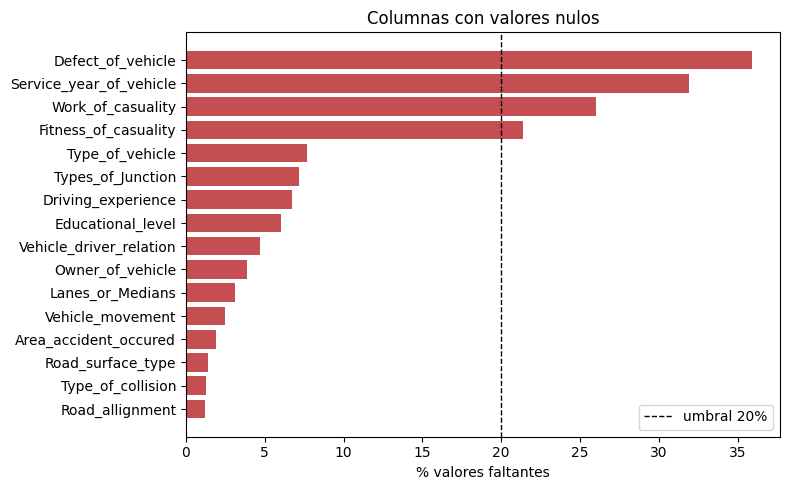

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
top_missing = missing_pct[missing_pct > 0]
ax.barh(top_missing.index[::-1], top_missing.values[::-1], color='#C44E52')
ax.axvline(20, color='black', ls='--', lw=1, label='umbral 20%')
ax.set_xlabel('% valores faltantes')
ax.set_title('Columnas con valores nulos')
ax.legend()
plt.tight_layout()
plt.show()

**Observación:** 16 de las 32 columnas tienen nulos. Cuatro superan el 20%: `Defect_of_vehicle` (35.9%), `Service_year_of_vehicle` (31.9%), `Work_of_casuality` (26.0%) y `Fitness_of_casuality` (21.4%). Con esa proporción de información ausente, cualquier imputación sería poco confiable, por lo que se excluyen. Las demás columnas con nulos no pasan del 7.7% (`Type_of_vehicle`).

## 5. Duplicados, valores atípicos y categorías raras

In [11]:
print('Filas duplicadas exactas en el crudo:', raw.duplicated().sum())

Filas duplicadas exactas en el crudo: 0


In [12]:
for c in ['Number_of_vehicles_involved', 'Number_of_casualties']:
    q1, q3 = raw[c].quantile([.25, .75])
    iqr = q3 - q1
    fuera = ((raw[c] < q1 - 1.5 * iqr) | (raw[c] > q3 + 1.5 * iqr)).sum()
    print(f'{c}: Q1={q1}, Q3={q3}, IQR={iqr} -> {fuera} valores fuera del rango IQR')
    print(raw[c].value_counts().sort_index().to_dict())

Number_of_vehicles_involved: Q1=2.0, Q3=2.0, IQR=0.0 -> 3976 valores fuera del rango IQR
{1: 1996, 2: 8340, 3: 1568, 4: 363, 6: 42, 7: 7}
Number_of_casualties: Q1=1.0, Q3=2.0, IQR=1.0 -> 720 valores fuera del rango IQR
{1: 8397, 2: 2290, 3: 909, 4: 394, 5: 207, 6: 89, 7: 22, 8: 8}


In [13]:
# Categorías raras (< 1% de los registros) por variable categórica
raras = {}
for c in raw.select_dtypes(exclude='number').columns.drop(['Time', 'Accident_severity']):
    vc = raw[c].value_counts(normalize=True)
    r = vc[vc < 0.01]
    if len(r):
        raras[c] = len(r)
pd.Series(raras, name='n_categorias_<1%').sort_values(ascending=False)

Cause_of_accident          6
Vehicle_movement           6
Pedestrian_movement        5
Type_of_vehicle            5
Area_accident_occured      5
Type_of_collision          5
Fitness_of_casuality       4
Road_allignment            4
Weather_conditions         4
Road_surface_conditions    2
Work_of_casuality          2
Educational_level          2
Types_of_Junction          2
Defect_of_vehicle          2
Light_conditions           1
Vehicle_driver_relation    1
Lanes_or_Medians           1
Casualty_severity          1
Owner_of_vehicle           1
Driving_experience         1
Road_surface_type          1
Name: n_categorias_<1%, dtype: int64

In [14]:
# Variables dominadas por una sola categoría (sobre valores no nulos)
dom = (raw.select_dtypes(exclude='number').drop(columns=['Time', 'Accident_severity'])
          .apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(1)
          .sort_values(ascending=False))
dom[dom > 80]

Fitness_of_casuality       99.2
Defect_of_vehicle          98.6
Road_surface_type          93.0
Sex_of_driver              92.9
Pedestrian_movement        92.5
Owner_of_vehicle           88.4
Road_allignment            85.9
Vehicle_driver_relation    82.0
Weather_conditions         81.7
dtype: float64

In [15]:
# Artefactos de codificación de texto en los nombres de categoría
raw['Type_of_vehicle'].dropna().loc[lambda s: s.str.contains(r'\?')].unique()

array(['Lorry (41?100Q)', 'Public (13?45 seats)', 'Lorry (11?40Q)'],
      dtype=object)

**Observación:**
- El crudo **no tiene filas duplicadas exactas**; la ausencia de duplicados se vuelve a verificar después de la limpieza (sección 6).
- Las dos variables numéricas son conteos pequeños: el criterio IQR marca como atípico todo lo distinto de 2 vehículos o de 1–2 víctimas, lo cual no tiene sentido para un conteo. Los valores (1–7 vehículos, 1–8 víctimas) son plausibles y se conservan.
- Al ser casi todo categórico, los "atípicos" relevantes son **categorías raras** (< 1% de los registros), presentes en muchas variables (p. ej. `Types_of_Junction = X Shape`, 12 filas). En el modelado se agrupan en una categoría "infrecuente" al codificar.
- Varias variables están **dominadas por una sola categoría** (sobre valores no nulos): `Road_surface_type` (93.0% *Asphalt roads*), `Sex_of_driver` (92.9% *Male*) y `Pedestrian_movement` (92.5% *Not a Pedestrian*), entre otras; su capacidad para distinguir entre clases será limitada.
- `Type_of_vehicle` tiene artefactos de codificación (`Lorry (41?100Q)`), que no afectan el análisis pero deben tenerse en cuenta al presentar resultados.

## 6. Limpieza reproducible → `cleaned.csv`

Reglas aplicadas:
1. **Eliminar columnas con más de 20% de nulos** (4 columnas, sección 4).
2. **Eliminar variables de la víctima o conocidas solo después del accidente**: `Casualty_class`, `Sex_of_casualty`, `Age_band_of_casualty`, `Casualty_severity` y `Number_of_casualties`. Describen a la víctima y no al evento, o dependen del desenlace, por lo que filtrarían información del target (fuga de información).
3. **Transformar `Time` en `Hour`** (hora del día, 0–23).
4. **Codificar los nulos restantes de variables categóricas como `'Unknown'`** (máximo 7.7% por columna). Varias columnas ya traían una categoría `'Unknown'` en la fuente, y ambas se fusionan.
5. **Codificar el target**: `0 = Fatal injury`, `1 = Serious Injury`, `2 = Slight Injury`.

In [16]:
high_null = missing_pct[missing_pct > 20].index.tolist()
post_evento = ['Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Number_of_casualties']

df = raw.drop(columns=high_null + post_evento).copy()
df.insert(0, 'Hour', pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour)
df = df.drop(columns='Time')

cat_cols = df.select_dtypes(exclude='number').columns.drop('Accident_severity')
df[cat_cols] = df[cat_cols].fillna('Unknown')

sev_code = {'Fatal injury': 0, 'Serious Injury': 1, 'Slight Injury': 2}
df['Accident_severity'] = df['Accident_severity'].map(sev_code)

predictoras = df.columns.drop('Accident_severity').tolist()
print('Columnas eliminadas:', high_null + post_evento + ['Time'])
print(f'Dataset depurado: {df.shape} -> {len(predictoras)} predictoras + target')
print('Categóricas:', len(cat_cols), '| Numéricas:', len(predictoras) - len(cat_cols), df[predictoras].select_dtypes('number').columns.tolist())
print('Nulos totales:', df.isnull().sum().sum(), '| Duplicados:', df.duplicated().sum())

Columnas eliminadas: ['Defect_of_vehicle', 'Service_year_of_vehicle', 'Work_of_casuality', 'Fitness_of_casuality', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Number_of_casualties', 'Time']
Dataset depurado: (12316, 23) -> 22 predictoras + target
Categóricas: 20 | Numéricas: 2 ['Hour', 'Number_of_vehicles_involved']
Nulos totales: 0 | Duplicados: 0


In [17]:
df.to_csv('cleaned.csv', index=False)
print('Guardado: cleaned.csv', df.shape)

Guardado: cleaned.csv (12316, 23)


**Observación:** el dataset depurado tiene **12,316 filas, 22 predictoras (20 categóricas + `Hour` y `Number_of_vehicles_involved`) y el target**, sin nulos ni duplicados. Se guarda como `cleaned.csv`, que es el archivo que usa `modelado.ipynb`.

In [18]:
grupos_vars = {
    'Conductor': ['Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Driving_experience', 'Vehicle_driver_relation'],
    'Vehículo': ['Type_of_vehicle', 'Owner_of_vehicle', 'Vehicle_movement'],
    'Vía': ['Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions'],
    'Entorno / evento': ['Hour', 'Day_of_week', 'Light_conditions', 'Weather_conditions', 'Type_of_collision',
                         'Number_of_vehicles_involved', 'Pedestrian_movement', 'Cause_of_accident'],
}
assert sorted(sum(grupos_vars.values(), [])) == sorted(predictoras)
pd.DataFrame({'n': {k: len(v) for k, v in grupos_vars.items()}, 'variables': {k: ', '.join(v) for k, v in grupos_vars.items()}})

,n,variables
Conductor,5,"Age_band_of_driver, Sex_of_driver, Educational..."
Vehículo,3,"Type_of_vehicle, Owner_of_vehicle, Vehicle_mov..."
Vía,6,"Area_accident_occured, Lanes_or_Medians, Road_..."
Entorno / evento,8,"Hour, Day_of_week, Light_conditions, Weather_c..."


**Observación:** las 22 predictoras se agrupan en cuatro categorías (Tabla I del paper): conductor (5), vehículo (3), vía (6) y entorno/evento (8).

## 7. Distribución de la variable objetivo y línea base (hallazgo A)

In [19]:
sev_map = {0: 'Fatal', 1: 'Serious', 2: 'Slight'}
df['sev_label'] = df['Accident_severity'].map(sev_map)
df['grave_fatal'] = (df['Accident_severity'] < 2).astype(int) * 100   # 100 si Serious o Fatal

counts = df['sev_label'].value_counts()
pct = (df['sev_label'].value_counts(normalize=True) * 100).round(1)
display(pd.DataFrame({'n': counts, '%': pct}))
print(f'Proporción general de lesiones graves o fatales: {df.grave_fatal.mean():.1f}%')
print(f'Razón de desbalance Slight/Fatal: {counts["Slight"] / counts["Fatal"]:.0f} : 1')

,n,%
sev_label,,
Slight,10415,84.6
Serious,1743,14.2
Fatal,158,1.3


Proporción general de lesiones graves o fatales: 15.4%
Razón de desbalance Slight/Fatal: 66 : 1


In [20]:
# Línea base: clasificador trivial que siempre predice la clase mayoritaria (Slight)
p = (df['sev_label'] == 'Slight').mean()
f1_slight = 2 * p * 1 / (p + 1)          # precisión = p, recall = 1
f1_macro = (f1_slight + 0 + 0) / 3        # F1 = 0 para Serious y Fatal
print(f'Exactitud de la línea base: {p:.1%}')
print(f'F1-macro de la línea base: {f1_macro:.2f}')

Exactitud de la línea base: 84.6%
F1-macro de la línea base: 0.31


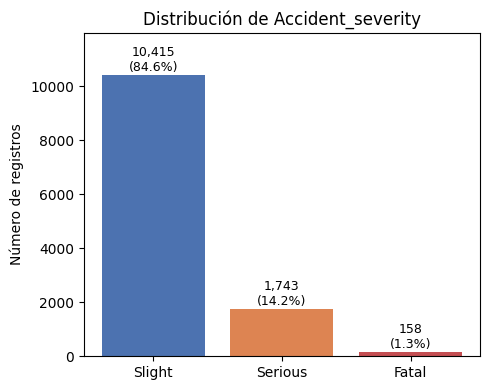

In [21]:
order = ['Slight', 'Serious', 'Fatal']
counts_ord = counts.reindex(order)
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(order, counts_ord.values, color=['#4C72B0', '#DD8452', '#C44E52'])
for i, v in enumerate(counts_ord.values):
    ax.text(i, v + 150, f'{v:,}\n({v / len(df) * 100:.1f}%)', ha='center', fontsize=9)
ax.set_title('Distribución de Accident_severity')
ax.set_ylabel('Número de registros')
ax.set_ylim(0, counts_ord.max() * 1.15)
plt.tight_layout()
plt.show()

**Observación clave (Hallazgo A; paper: Sección V, Tabla II y Fig. 1(a)):** el target está fuertemente desbalanceado: **84.6%** Slight (10,415), **14.2%** Serious (1,743) y **1.3%** Fatal (158); la razón Slight/Fatal es de 66 a 1. En total, **15.4%** de los registros terminan en lesión grave o fatal. Un clasificador trivial que siempre predice *Slight* obtiene **84.6% de exactitud** pero un **F1-macro de apenas 0.31**, por lo que la exactitud global no sirve como métrica: el modelado (`modelado.ipynb`) usa F1-macro y recall por clase, y compara estrategias frente al desbalance.

## 8. Asociación de cada predictora con la severidad (χ² y V de Cramér)

In [22]:
filas = []
for c in predictoras:
    t = pd.crosstab(df[c], df['Accident_severity'])
    chi2, pval, dof, expected = chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    filas.append({'variable': c, 'n_categorias': t.shape[0], 'chi2': round(chi2, 1),
                  'p_valor': pval, 'V_Cramer': round(v, 3),
                  '%_celdas_esperado<5': round((expected < 5).mean() * 100, 1)})
assoc = pd.DataFrame(filas).sort_values('V_Cramer', ascending=False).reset_index(drop=True)
assoc['significativa_5%'] = assoc['p_valor'] < 0.05
assoc

,variable,n_categorias,chi2,p_valor,V_Cramer,%_celdas_esperado<5,significativa_5%
0,Number_of_vehicles_involved,6,317.5,3.013343e-62,0.114,22.2,True
1,Hour,24,176.7,3.314056e-17,0.085,11.1,True
2,Age_band_of_driver,5,60.5,3.673673e-10,0.050,0.0,True
3,Types_of_Junction,8,57.2,3.638729e-07,0.048,16.7,True
4,Cause_of_accident,20,49.1,1.075290e-01,0.045,23.3,False
5,Type_of_vehicle,18,46.9,6.909269e-02,0.044,18.5,False
6,Area_accident_occured,14,46.8,7.388156e-03,0.044,26.2,True
7,Day_of_week,7,47.2,4.300319e-06,0.044,0.0,True
8,Light_conditions,4,45.0,4.627954e-08,0.043,16.7,True
9,Weather_conditions,9,41.8,4.296262e-04,0.041,29.6,True


In [23]:
print('Variables con asociación significativa (p < 0.05):', assoc['significativa_5%'].sum(), 'de', len(assoc))
print('V de Cramér máximo:', assoc['V_Cramer'].max(), '(', assoc.loc[0, 'variable'], ')')
print('Cause_of_accident -> p =', round(assoc.set_index('variable').loc['Cause_of_accident', 'p_valor'], 3))

Variables con asociación significativa (p < 0.05): 8 de 22
V de Cramér máximo: 0.114 ( Number_of_vehicles_involved )
Cause_of_accident -> p = 0.108


**Observación:** **8 de las 22 predictoras** muestran asociación estadísticamente significativa con la severidad (p < 0.05), pero **todas las asociaciones individuales son débiles** (V de Cramér ≤ 0.11). Las más fuertes son `Number_of_vehicles_involved` (V = 0.114) y `Hour` (V = 0.085). `Cause_of_accident` **no** resulta significativa (p = 0.11), pese a que algunas causas puntuales muestran proporciones altas (sección 10).

Advertencias: (i) varias tablas tienen celdas con frecuencia esperada < 5 (por las categorías raras), lo que hace la prueba χ² solo aproximada; (ii) las filas del mismo siniestro no son independientes (sección 2), así que los p-valores son optimistas. Aun así, el patrón general indica que **ninguna variable por sí sola separa bien las clases** y que el modelo tendrá que combinar muchas señales débiles.

## 9. Número de vehículos involucrados vs. severidad (hallazgo B)

In [24]:
nveh = df['Number_of_vehicles_involved'].clip(upper=4).map({1: '1', 2: '2', 3: '3', 4: '4 o más'})
ct_veh = df.groupby(nveh).agg(n=('grave_fatal', 'size'),
                              pct_grave_fatal=('grave_fatal', 'mean'),
                              pct_fatal=('Accident_severity', lambda s: (s == 0).mean() * 100)).round(1)
ct_veh

,n,pct_grave_fatal,pct_fatal
Number_of_vehicles_involved,,,
1,1996,28.2,2.2
2,8340,12.8,1.2
3,1568,14.1,0.7
4 o más,412,12.4,0.0


In [25]:
df.groupby('Number_of_vehicles_involved').agg(n=('grave_fatal', 'size'), pct_grave_fatal=('grave_fatal', 'mean')).round(1)

,n,pct_grave_fatal
Number_of_vehicles_involved,,
1,1996,28.2
2,8340,12.8
3,1568,14.1
4,363,10.7
6,42,28.6
7,7,0.0


**Observación clave (Hallazgo B; paper: Sección V y Fig. 1(b)):** los siniestros con **un solo vehículo** (n = 1,996) terminan en lesión grave o fatal en el **28.2%** de los casos, más del doble que los de **dos vehículos** (12.8%, n = 8,340); también tienen la mayor proporción de fatales (2.2% frente a 1.2%). Es la variable con la asociación más fuerte (sección 8) y es información disponible desde el primer reporte del accidente, lo que la hace útil para el caso de uso de priorización de emergencias. (Las categorías de 6 y 7 vehículos tienen muy pocos casos, n = 42 y 7, y no se interpretan por separado.)

## 10. Condiciones de luz y hora del día vs. severidad (hallazgo C)

In [26]:
ct_light = pd.crosstab(df['Light_conditions'], df['sev_label'], normalize='index') * 100
ct_light['n'] = df['Light_conditions'].value_counts()
ct_light['Serious+Fatal'] = ct_light['Serious'] + ct_light['Fatal']
ct_light.sort_values('Serious+Fatal', ascending=False).round(1)

sev_label,Fatal,Serious,Slight,n,Serious+Fatal
Light_conditions,,,,,
Darkness - no lighting,2.6,25.5,71.9,192,28.1
Darkness - lights unlit,0.0,17.5,82.5,40,17.5
Darkness - lights lit,2.0,14.2,83.8,3286,16.2
Daylight,1.0,13.9,85.1,8798,14.9


In [27]:
franja = pd.cut(df['Hour'], bins=[-1, 5, 11, 17, 23], labels=['00-05', '06-11', '12-17', '18-23'])
df.groupby(franja, observed=True).agg(n=('grave_fatal', 'size'),
                                      pct_grave_fatal=('grave_fatal', 'mean'),
                                      pct_fatal=('Accident_severity', lambda s: (s == 0).mean() * 100)).round(1)

,n,pct_grave_fatal,pct_fatal
Hour,,,
00-05,675,20.1,2.5
06-11,3236,14.0,0.8
12-17,5125,14.4,1.0
18-23,3280,17.6,2.0


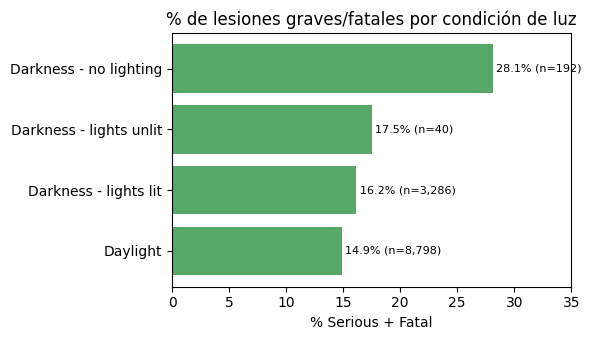

In [28]:
ct_sorted = ct_light.sort_values('Serious+Fatal')
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(ct_sorted.index, ct_sorted['Serious+Fatal'], color='#55A868')
for y, (v, n) in enumerate(zip(ct_sorted['Serious+Fatal'], ct_sorted['n'])):
    ax.text(v + 0.3, y, f'{v:.1f}% (n={n:,})', va='center', fontsize=8)
ax.set_xlabel('% Serious + Fatal')
ax.set_xlim(0, 35)
ax.set_title('% de lesiones graves/fatales por condición de luz')
plt.tight_layout()
plt.show()

**Observación (Hallazgo C, complementario; en el paper solo se menciona en la Sección V):** en **oscuridad sin alumbrado** (*Darkness - no lighting*) la proporción de lesiones graves o fatales es **28.1%**, casi el doble que con luz de día (**14.9%**). Hay que tomarlo con cautela porque ese grupo es pequeño (n = 192). El patrón es coherente con la hora del día, que no depende de ese grupo pequeño: en la **madrugada (00–05 h)** la proporción es **20.1%** (n = 675), frente a **14.0%** en la mañana (06–11 h). Tanto la luz como la hora tienen asociación significativa con la severidad (sección 8).

## 11. Complementos: causa del accidente y tipo de intersección

In [29]:
ct_cause = pd.crosstab(df['Cause_of_accident'], df['sev_label'], normalize='index') * 100
ct_cause['n'] = df['Cause_of_accident'].value_counts()
ct_cause['Serious+Fatal'] = ct_cause['Serious'] + ct_cause['Fatal']
ct_cause.sort_values('Serious+Fatal', ascending=False).round(1).head(10)

sev_label,Fatal,Serious,Slight,n,Serious+Fatal
Cause_of_accident,,,,,
Overspeed,1.6,24.6,73.8,61,26.2
Overloading,3.4,16.9,79.7,59,20.3
Driving to the left,1.4,18.7,79.9,284,20.1
Driving at high speed,1.1,17.8,81.0,174,19.0
Overtaking,0.9,17.4,81.6,430,18.4
Overturning,1.3,15.4,83.2,149,16.8
Moving Backward,2.3,14.2,83.5,1137,16.5
Driving carelessly,1.6,14.9,83.5,1402,16.5
Getting off the vehicle improperly,1.5,14.7,83.8,197,16.2


**Observación:** algunas causas puntuales tienen proporciones altas de lesiones graves o fatales, como exceso de velocidad (*Overspeed*, **26.2%**) y sobrecarga (*Overloading*, **20.3%**), frente al 15.4% general. Sin embargo, son grupos pequeños (n = 61 y n = 59) y la variable en conjunto **no** tiene asociación significativa con la severidad (p = 0.11, sección 8). No se reporta como hallazgo principal.

In [30]:
ct_junction = pd.crosstab(df['Types_of_Junction'], df['sev_label'], normalize='index') * 100
ct_junction['n'] = df['Types_of_Junction'].value_counts()
ct_junction['Serious+Fatal'] = ct_junction['Serious'] + ct_junction['Fatal']
ct_junction.sort_values('Serious+Fatal', ascending=False).round(1)

sev_label,Fatal,Serious,Slight,n,Serious+Fatal
Types_of_Junction,,,,,
Other,0.4,18.7,80.9,445,19.1
Unknown,1.8,15.6,82.7,1078,17.3
No junction,1.9,15.1,83.0,3837,17.0
O Shape,0.6,15.9,83.5,164,16.5
Y Shape,1.2,13.9,84.9,4543,15.1
Crossing,0.6,11.3,88.2,2177,11.8
T Shape,0.0,11.7,88.3,60,11.7
X Shape,0.0,0.0,100.0,12,0.0


**Observación:** el tipo de intersección sí tiene asociación significativa (sección 8). Los siniestros en tramos **sin intersección** (`No junction`) muestran 17.0% de lesiones graves o fatales, frente a 11.8% en **cruces de vías** (`Crossing`). Nota de interpretación: en este dataset `Crossing` es un cruce entre vías (intersección), no un paso peatonal, y el dataset no registra si la intersección está señalizada, así que no se puede atribuir la diferencia a la señalización. Una hipótesis a explorar es la mayor velocidad fuera de las intersecciones. La categoría `Unknown` (1,078 filas) mezcla nulos originales y la categoría *Unknown* de la fuente.

## 12. Figuras: Fig. 1 del paper y figura complementaria

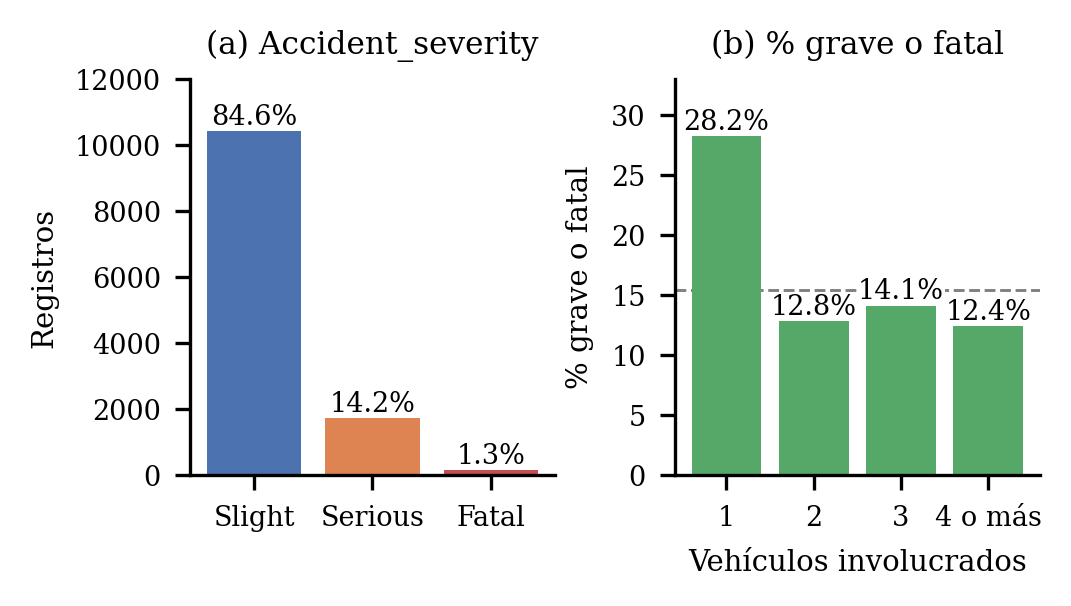

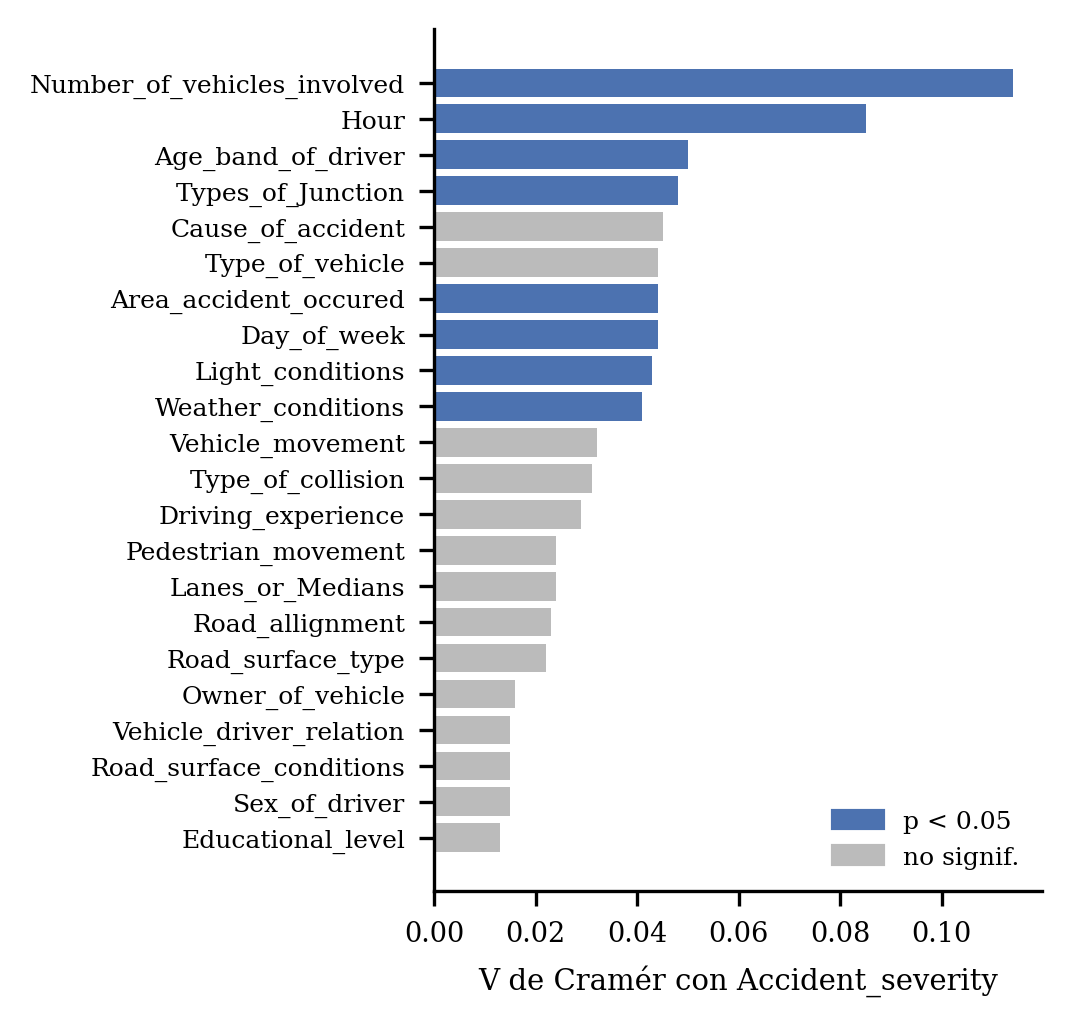

In [31]:
os.makedirs('figuras', exist_ok=True)
plt.rcParams.update({'font.family': 'serif', 'font.size': 7, 'axes.titlesize': 7.5,
                     'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5})

# Fig. 1: (a) distribución del target, (b) % grave/fatal por número de vehículos
fig, axes = plt.subplots(1, 2, figsize=(3.45, 1.9), dpi=300)
ax = axes[0]
ax.bar(order, counts_ord.values, color=['#4C72B0', '#DD8452', '#C44E52'])
for i, v in enumerate(counts_ord.values):
    ax.text(i, v + 200, f'{v / len(df) * 100:.1f}%', ha='center', fontsize=6.5)
ax.set_ylim(0, 12000)
ax.set_ylabel('Registros')
ax.set_title('(a) Accident_severity')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.bar(ct_veh.index, ct_veh['pct_grave_fatal'], color='#55A868')
for i, (v, n) in enumerate(zip(ct_veh['pct_grave_fatal'], ct_veh['n'])):
    ax.text(i, v + 0.6, f'{v:.1f}%', ha='center', fontsize=6.5,
            bbox=dict(facecolor='white', edgecolor='none', pad=0.3))
ax.axhline(df.grave_fatal.mean(), color='gray', ls='--', lw=0.7, zorder=0)
ax.set_ylim(0, 33)
ax.set_xlabel('Vehículos involucrados')
ax.set_ylabel('% grave o fatal')
ax.set_title('(b) % grave o fatal')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(pad=0.4)
fig.savefig('figuras/fig1_target_vehiculos.png', dpi=300)
plt.show()

# Figura complementaria (no incluida en el paper): V de Cramér de cada predictora (significativas en color)
a = assoc.sort_values('V_Cramer')
fig, ax = plt.subplots(figsize=(3.45, 3.3), dpi=300)
colores = np.where(a['significativa_5%'], '#4C72B0', '#BBBBBB')
ax.barh(a['variable'], a['V_Cramer'], color=colores)
ax.set_xlabel('V de Cramér con Accident_severity')
ax.tick_params(axis='y', labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#4C72B0', label='p < 0.05'), Patch(color='#BBBBBB', label='no signif.')],
          fontsize=6, frameon=False, loc='lower right')
plt.tight_layout(pad=0.4)
fig.savefig('figuras/fig2_cramer.png', dpi=300)
plt.show()
plt.rcParams.update(plt.rcParamsDefault)

**Observación:** la primera figura es la **Fig. 1 del paper**, en el tamaño de una columna IEEE: resume el hallazgo A (desbalance: 84.6 / 14.2 / 1.3%) y el hallazgo B (28.2% de lesiones graves o fatales con un solo vehículo, frente al promedio de 15.4%, línea punteada). La segunda es **complementaria** (el paper solo cita su conclusión en la Sección V): ordena las 22 predictoras por su V de Cramér (sección 8); solo 8 son significativas (en azul) y ninguna supera 0.12, lo que muestra que la señal está repartida en muchas variables débiles.

## 13. Conclusión del EDA

- El dataset depurado (`cleaned.csv`: 12,316 registros, 22 predictoras, sin nulos ni duplicados) permite plantear el problema como **clasificación supervisada multiclase** sobre `Accident_severity`.
- **Reto principal (Hallazgo A):** desbalance severo (84.6 / 14.2 / 1.3%). La línea base trivial obtiene 84.6% de exactitud pero F1-macro de 0.31, que es el piso a superar en el modelado.
- **Señal disponible (Hallazgos B y C):** el número de vehículos involucrados, la hora y las condiciones de luz se asocian con la severidad, aunque todas las asociaciones individuales son débiles (V ≤ 0.11). El modelo tendrá que combinar varias variables.
- **Limitación de granularidad:** cada fila es un conductor/vehículo y varias filas pueden pertenecer al mismo siniestro (~5,272 eventos aproximados), lo que exige una validación por grupos (aplicada en `modelado.ipynb`).